# 03 ตรวจตำแหน่ง slice (x, y, z) และ hippocampus บน volume ที่ล็อก (128 × 128 × 96)

In [1]:
import sys
# ติดตั้ง library ที่ notebook นี้ต้องใช้ (ไม่แตะ torch / numpy / pandas ที่มีอยู่แล้ว เพื่อกันเวอร์ชันพัง)
!{sys.executable} -m pip install --quiet --user nibabel nilearn scipy scikit-learn matplotlib
# atlasreader ใช้เฉพาะ "ไฟล์ atlas ที่แถมมา" ไม่ import ตัวแพ็กเกจ จึงใช้ --no-deps
!{sys.executable} -m pip install --quiet --user --no-deps atlasreader

In [2]:
import os, json, itertools, warnings, importlib.util
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates, binary_fill_holes
from scipy.optimize import minimize
warnings.filterwarnings("ignore")

import processing_lock as pl            # ไฟล์ล็อก preprocessing (ต้องอยู่โฟลเดอร์เดียวกัน)

from matplotlib import font_manager as fm          # ฟอนต์ไทยสำหรับชื่อแกน/หัวข้อในกราฟ
_have = {f.name for f in fm.fontManager.ttflist}
_thai = [f for f in ("Noto Sans Thai", "Tahoma", "Leelawadee UI", "TH Sarabun New", "Sarabun", "Loma", "Garuda", "Norasi") if f in _have]
if _thai: plt.rcParams["font.family"] = _thai[0]
else: print("ไม่พบฟอนต์ไทยใน matplotlib: ตัวอักษรไทยในกราฟอาจเป็นกล่อง (ไม่กระทบตัวเลข)")
plt.rcParams["axes.unicode_minus"] = False

SPLIT_PATH   = "split.json"
DATA_ROOT    = pl.DATA_ROOT             # ไม่ตรงกับเครื่องคุณ ให้แก้ที่นี่
CACHE_DIR    = "."                      # โฟลเดอร์ที่มี locked_volumes_*.npy (ถ้าไม่มี จะโหลดจากไฟล์ภาพโดยตรง)
N_SUBJECTS   = 30                       # จำนวนคนที่ใช้ตรวจ (None = ทุกคน)
HIP_THRESHOLD = 50                      # ความน่าจะเป็น (%) ของ atlas ที่นับว่าเป็น hippocampus
SEED         = 1334
OUT_DIR      = "slice_check_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print(pl.describe())

ไม่พบฟอนต์ไทยใน matplotlib: ตัวอักษรไทยในกราฟอาจเป็นกล่อง (ไม่กระทบตัวเลข)
processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)


## 1) โหลด volume ที่ล็อกแล้ว

In [3]:
ids_all = sorted(json.load(open(SPLIT_PATH))["labels"].keys())
rng = np.random.default_rng(SEED)
ids = ids_all if N_SUBJECTS is None else sorted(rng.choice(ids_all, size=min(N_SUBJECTS, len(ids_all)), replace=False).tolist())

if os.path.exists(os.path.join(CACHE_DIR, pl.CACHE_NAME)):
    vols = pl.load_locked(ids, CACHE_DIR)
else:
    print("ไม่พบ cache -> โหลดจากไฟล์ภาพโดยตรง (ช้ากว่า)")
    vols = np.stack([pl.load_volume(s, DATA_ROOT) for s in ids])
CENTER = pl.CENTER
print("volumes:", vols.shape, "| ตำแหน่งกลาง (x,y,z) =", CENTER)

ไม่พบ cache -> โหลดจากไฟล์ภาพโดยตรง (ช้ากว่า)
volumes: (30, 128, 128, 96) | ตำแหน่งกลาง (x,y,z) = (64, 64, 48)


## 2) ตำแหน่งกลางเทียบกับ slice ที่มีเนื้อสมองมากที่สุด (ทั้งสามแกน)

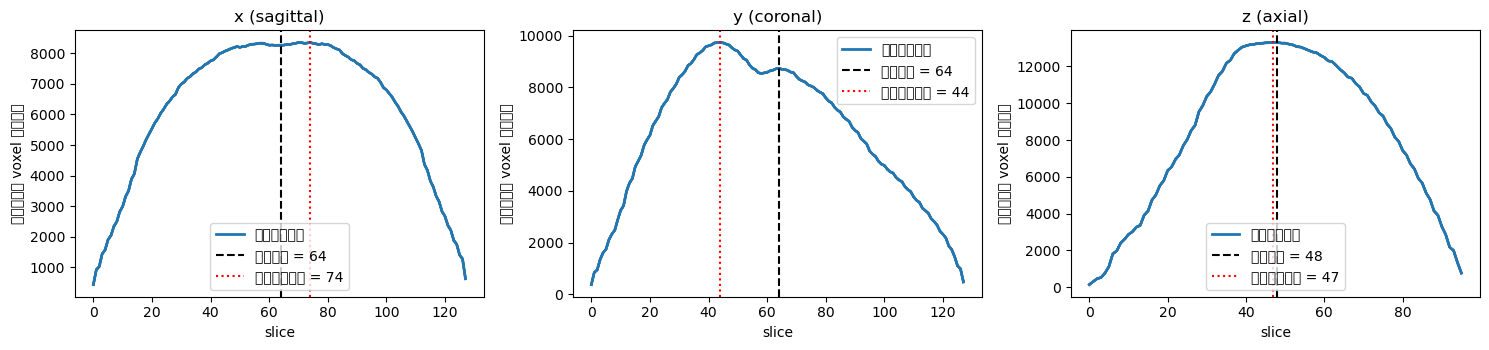

,แกน,ขนาด,ตำแหน่งกลาง,slice ที่สมองมากสุด,ต่างจากกลาง (slice),มีสมองตั้งแต่,ถึง
0,x (sagittal),128,64,74,10,0,127
1,y (coronal),128,64,44,-20,0,127
2,z (axial),96,48,47,-1,0,95


In [4]:
AX = ["x (sagittal)", "y (coronal)", "z (axial)"]
OTHER = [(1, 2), (0, 2), (0, 1)]          # รวม voxel ตามแกนอื่น เหลือเส้นของแกนนั้น
cnt = [np.stack([(v > 0).sum(axis=OTHER[k]) for v in vols]) for k in range(3)]

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
rows = []
for k in range(3):
    m = cnt[k].mean(0)
    axs[k].plot(cnt[k].T, color="gray", alpha=.25)
    axs[k].plot(m, color="C0", lw=2, label="เฉลี่ย")
    axs[k].axvline(CENTER[k], color="k", ls="--", label=f"กลาง = {CENTER[k]}")
    axs[k].axvline(int(m.argmax()), color="r", ls=":", label=f"มากสุด = {int(m.argmax())}")
    axs[k].set_title(AX[k]); axs[k].set_xlabel("slice"); axs[k].set_ylabel("จำนวน voxel สมอง"); axs[k].legend()
    present = np.where(m > 0)[0]
    rows.append({"แกน": AX[k], "ขนาด": vols.shape[k + 1], "ตำแหน่งกลาง": CENTER[k],
                 "slice ที่สมองมากสุด": int(m.argmax()), "ต่างจากกลาง (slice)": int(m.argmax() - CENTER[k]),
                 "มีสมองตั้งแต่": int(present[0]), "ถึง": int(present[-1])})
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/brain_voxel_per_slice.png", dpi=130); plt.show()
table_pos = pd.DataFrame(rows); table_pos

## 3) ดูทุก slice ของแกน x และ y (คนแรก) เหมือน `plot_all_slices` ของแกน z ในไฟล์ review

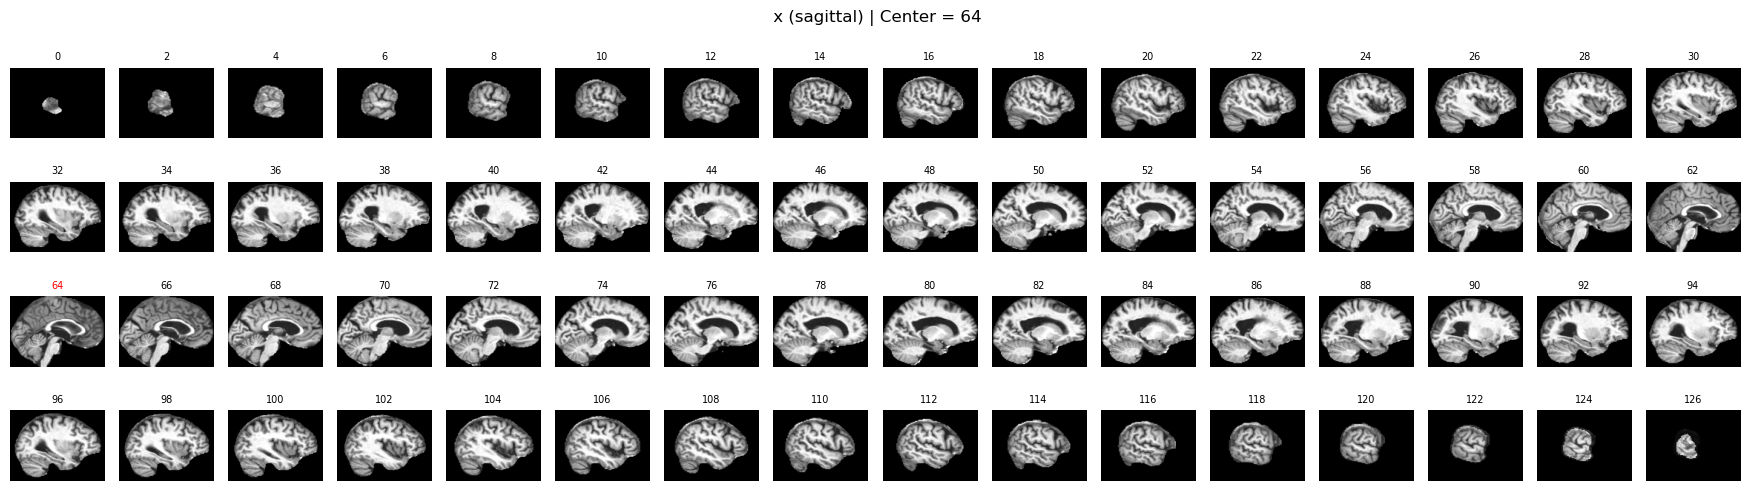

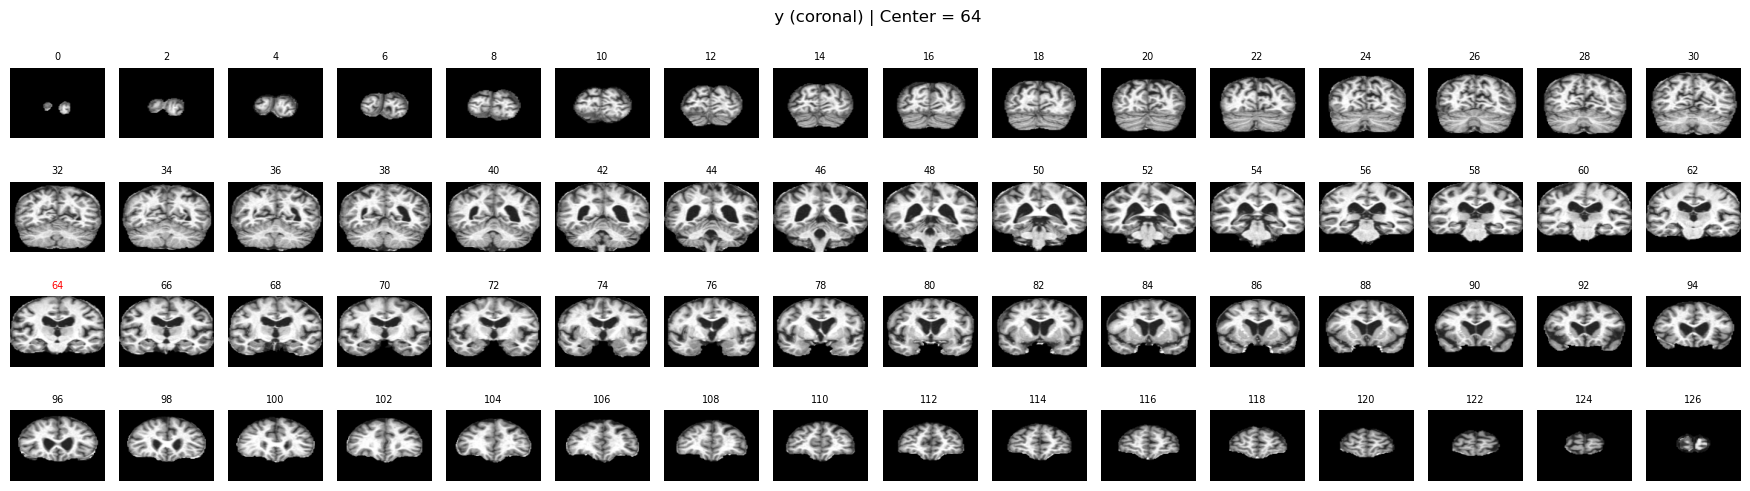

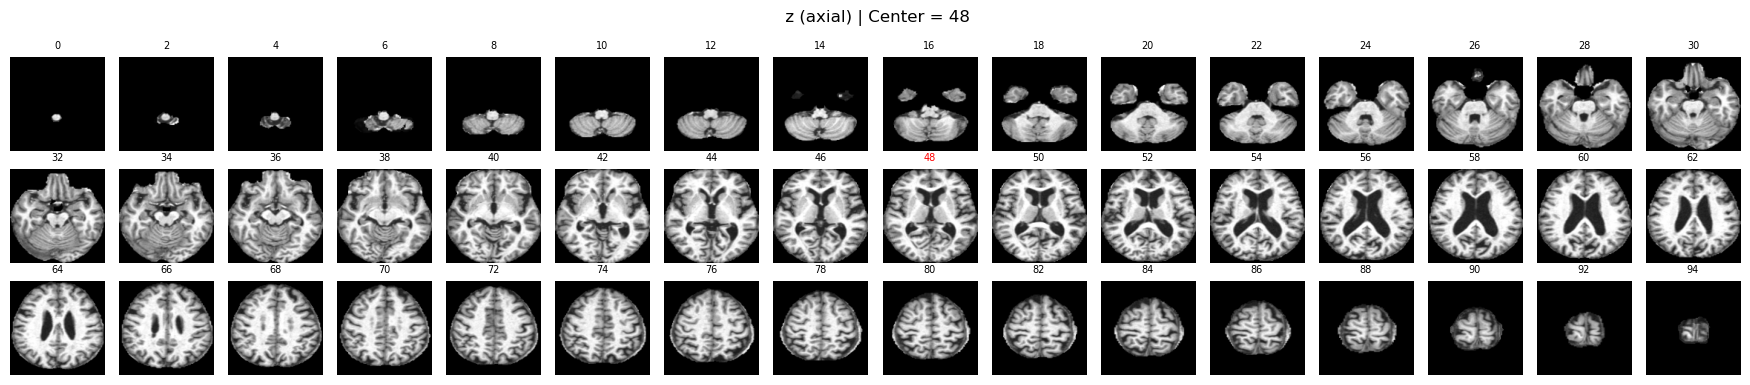

In [5]:
def plot_all_slices_axis(v, axis, center, step=2, cols=16):
    idx = list(range(0, v.shape[axis], step))
    if center not in idx: idx.append(center)
    idx = sorted(idx)
    rows_ = int(np.ceil(len(idx) / cols))
    fig, axs = plt.subplots(rows_, cols, figsize=(cols * 1.1, rows_ * 1.3)); axs = np.atleast_1d(axs).flatten()
    for a, i in zip(axs, idx):
        a.imshow(np.take(v, i, axis=axis).T, cmap="gray", origin="lower")
        a.set_title(i, fontsize=7, color="red" if i == center else "black"); a.axis("off")
    for a in axs[len(idx):]: a.axis("off")
    plt.suptitle(f" {AX[axis]} | Center = {center}"); plt.tight_layout(); return fig

for k in (0, 1, 2):
    f = plot_all_slices_axis(vols[0], k, CENTER[k]); f.savefig(f"{OUT_DIR}/all_slices_axis{k}.png", dpi=110); plt.show()

## 4) หาตำแหน่ง hippocampus (โดยประมาณ) บน volume ที่ล็อก

In [6]:
def load_hippocampus_prob():
    import nibabel as nib
    spec = importlib.util.find_spec("atlasreader")
    if spec is None:
        raise ImportError("ต้อง pip install atlasreader ก่อน (ใช้เฉพาะไฟล์ atlas ที่แถมมา)")
    base = os.path.join(list(spec.submodule_search_locations)[0], "data", "atlases")
    im = nib.load(os.path.join(base, "atlas_harvard_oxford.nii.gz"))
    lab = pd.read_csv(os.path.join(base, "labels_harvard_oxford.csv"))
    idx = {n: int(i) for i, n in zip(lab["index"], lab["name"])}
    L, R = idx["Left_Hippocampus"], idx["Right_Hippocampus"]
    return np.asarray(im.dataobj[..., L], dtype=np.float32), np.asarray(im.dataobj[..., R], dtype=np.float32), im.affine

def load_mni_mask():
    from nilearn import datasets
    try:
        img = datasets.load_mni152_brain_mask(resolution=2)
    except TypeError:
        img = datasets.load_mni152_brain_mask()
    return (np.asarray(img.dataobj) > 0).astype(np.float32), img.affine

def vox_to_mm(aff, p):                      # p: (3, n) พิกัด voxel -> mm
    return aff[:3, :3] @ p + aff[:3, 3:4]

def mm_to_vox(aff, m):
    inv = np.linalg.inv(aff)
    return inv[:3, :3] @ m + inv[:3, 3:4]

def rot_matrix(rx, ry, rz):
    rx, ry, rz = np.deg2rad([rx, ry, rz])
    Rx = np.array([[1, 0, 0], [0, np.cos(rx), -np.sin(rx)], [0, np.sin(rx), np.cos(rx)]])
    Ry = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
    Rz = np.array([[np.cos(rz), -np.sin(rz), 0], [np.sin(rz), np.cos(rz), 0], [0, 0, 1]])
    return Rz @ Ry @ Rx

def bbox(mask):
    nz = np.argwhere(mask > 0.5)
    return nz.min(0).astype(float), nz.max(0).astype(float)

def make_mapper(perm, sign, theta, c_s, size_s, c_m, size_m):
    """พิกัด voxel ของ volume ที่ล็อก (3,n) -> พิกัด mm ในปริภูมิ MNI"""
    s = np.exp(theta[0:3]); R = rot_matrix(*theta[3:6]); t = np.asarray(theta[6:9])
    def f(P):
        u = (P - c_s[:, None]) / size_s[:, None]
        base = np.stack([c_m[k] + sign[k] * u[perm[k]] * size_m[k] for k in range(3)])
        return (R @ (s[:, None] * (base - c_m[:, None]))) + c_m[:, None] + t[:, None]
    return f

def fit_to_mni(mean_mask, mni_mask, mni_aff, step=2):
    lo_s, hi_s = bbox(mean_mask); c_s = (lo_s + hi_s) / 2; size_s = hi_s - lo_s + 1
    lo_m, hi_m = bbox(mni_mask)
    mm_lo, mm_hi = vox_to_mm(mni_aff, lo_m[:, None])[:, 0], vox_to_mm(mni_aff, hi_m[:, None])[:, 0]
    c_m = (mm_lo + mm_hi) / 2; size_m = np.abs(mm_hi - mm_lo) + np.abs(np.diag(mni_aff)[:3])
    grids = np.meshgrid(*[np.arange(0, n, step) for n in mean_mask.shape], indexing="ij")
    P = np.stack([g.ravel().astype(float) for g in grids])
    target = mean_mask[::step, ::step, ::step].ravel()

    def dice(mapper):
        w = map_coordinates(mni_mask, mm_to_vox(mni_aff, mapper(P)), order=1, mode="constant", cval=0)
        return 2 * (w * target).sum() / (w.sum() + target.sum() + 1e-8)

    cands = []
    for perm in itertools.permutations(range(3)):
        for sign in itertools.product([1, -1], repeat=3):
            cands.append((dice(make_mapper(perm, sign, np.zeros(9), c_s, size_s, c_m, size_m)), perm, sign))
    cands.sort(key=lambda x: -x[0])
    best = None
    bounds = [(-.3, .3)] * 3 + [(-20, 20)] * 3 + [(-20, 20)] * 3
    for d0, perm, sign in cands[:3]:
        fun = lambda th: -dice(make_mapper(perm, sign, th, c_s, size_s, c_m, size_m))
        res = minimize(fun, np.zeros(9), method="Powell", bounds=bounds, options={"maxiter": 6, "xtol": 1e-2, "ftol": 1e-4})
        if best is None or -res.fun > best[0]:
            best = (-res.fun, perm, sign, res.x, d0)
    d, perm, sign, th, d0 = best
    return make_mapper(perm, sign, th, c_s, size_s, c_m, size_m), {"dice": float(d), "dice_before_refine": float(d0),
            "perm": perm, "sign": sign, "theta": th, "top3_init": [(round(c[0], 3), c[1], c[2]) for c in cands[:3]]}

# (ก) mask สมองเฉลี่ยของ volume ที่ล็อก
masks = np.stack([binary_fill_holes(v > 0) for v in vols]).astype(np.float32)
mean_mask = (masks.mean(0) >= 0.5).astype(np.float32)
# (ข) fit MNI -> volume ที่ล็อก
mni_mask, mni_aff = load_mni_mask()
mapper, info = fit_to_mni(mean_mask, mni_mask, mni_aff)
names = ["x (ซ้าย-ขวา)", "y (หน้า-หลัง)", "z (บน-ล่าง)"]
print(f"Dice ของการจัดตำแหน่งสมอง = {info['dice']:.3f}  (ก่อน refine {info['dice_before_refine']:.3f})")
for k in range(3):
    print(f"  แกน MNI {names[k]} <- แกนอาร์เรย์ {info['perm'][k]} ({'กลับทิศ' if info['sign'][k] < 0 else 'ทิศเดียวกัน'})")
if info["dice"] < 0.85:
    print("คำเตือน: Dice ต่ำกว่า 0.85 ตำแหน่ง hippocampus ที่ได้อาจคลาดเคลื่อนมาก ใช้ด้วยความระวัง")

Dice ของการจัดตำแหน่งสมอง = 0.969  (ก่อน refine 0.940)
  แกน MNI x (ซ้าย-ขวา) <- แกนอาร์เรย์ 0 (ทิศเดียวกัน)
  แกน MNI y (หน้า-หลัง) <- แกนอาร์เรย์ 1 (ทิศเดียวกัน)
  แกน MNI z (บน-ล่าง) <- แกนอาร์เรย์ 2 (ทิศเดียวกัน)


In [7]:
# (ค) ดึง hippocampus กลับมาที่ volume ที่ล็อก
pL, pR, ho_aff = load_hippocampus_prob()
grids = np.meshgrid(*[np.arange(n) for n in mean_mask.shape], indexing="ij")
P_all = np.stack([g.ravel().astype(float) for g in grids])
ho_vox = mm_to_vox(ho_aff, mapper(P_all))
probL = map_coordinates(pL, ho_vox, order=1, mode="constant", cval=0).reshape(mean_mask.shape)
probR = map_coordinates(pR, ho_vox, order=1, mode="constant", cval=0).reshape(mean_mask.shape)
hipA, hipB = probL >= HIP_THRESHOLD, probR >= HIP_THRESHOLD      # ซ้าย/ขวาของ atlas (ฝั่งไหนอยู่ x ต่ำ/สูง ดูจากตารางล่าง)
hip = hipA | hipB
print("จำนวน voxel hippocampus ใน volume ที่ล็อก:", int(hip.sum()), "| ซ้าย", int(hipA.sum()), "| ขวา", int(hipB.sum()))
# mask MNI ที่ fit แล้ว (ไว้ดูคุณภาพการจัดตำแหน่ง)
warped_mni = map_coordinates(mni_mask, mm_to_vox(mni_aff, mapper(P_all)), order=1, mode="constant", cval=0).reshape(mean_mask.shape) > 0.5

จำนวน voxel hippocampus ใน volume ที่ล็อก: 3576 | ซ้าย 1748 | ขวา 1828


## 5) ตำแหน่งกลางผ่าน hippocampus ไหม

,แกน,ช่วง slice ที่มี hippocampus,slice ที่มากสุด,ตำแหน่งกลางที่ใช้,กลางอยู่ในช่วงไหม,voxel ที่กลาง / ที่สูงสุด
0,x (sagittal),32-98,89,64,ใช่,0 / 146
1,y (coronal),46-74,66,64,ใช่,189 / 213
2,z (axial),27-47,33,48,ไม่ (ห่าง 1 slice),0 / 356


จุดศูนย์กลาง hippocampus: x = 41 และ 88 (กลางสมอง = 64) | y = 62 (กลางที่ใช้ 64) | z = 35 (กลางที่ใช้ 48)
ห่างจากตำแหน่งกลางที่ใช้อยู่: x -23 / +24 slice | y -2 slice | z -13 slice
(เทียบ: ความหนาของ hippocampus ต่อแกนราว x 23, y 29, z 21 slice)


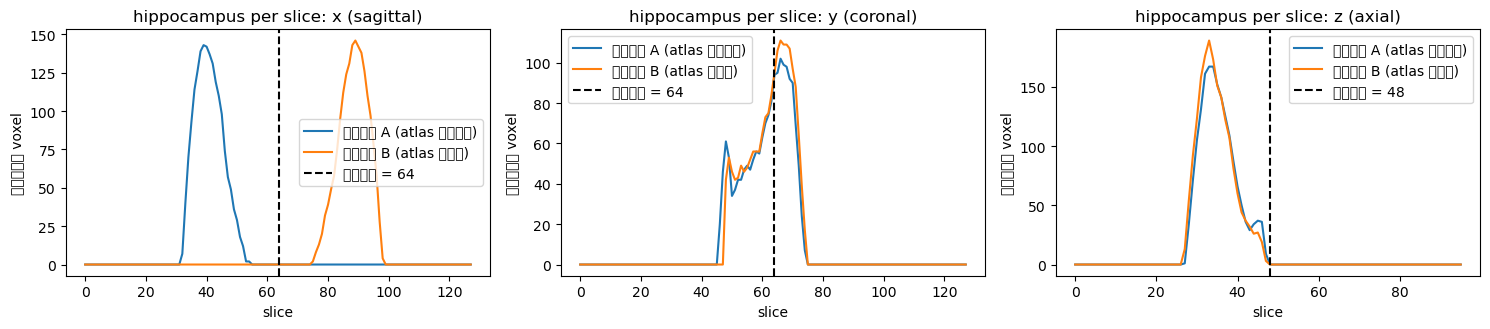

In [8]:
def prof(mask, k): return mask.sum(axis=OTHER[k])
rows = []
for k in range(3):
    p = prof(hip, k); nz = np.where(p > 0)[0]; lo, hi = int(nz.min()), int(nz.max()); c = CENTER[k]
    dist = 0 if lo <= c <= hi else int(min(abs(c - lo), abs(c - hi)))
    rows.append({"แกน": AX[k], "ช่วง slice ที่มี hippocampus": f"{lo}-{hi}", "slice ที่มากสุด": int(p.argmax()),
                 "ตำแหน่งกลางที่ใช้": c, "กลางอยู่ในช่วงไหม": "ใช่" if dist == 0 else f"ไม่ (ห่าง {dist} slice)",
                 "voxel ที่กลาง / ที่สูงสุด": f"{int(p[c])} / {int(p.max())}"})
table_hip = pd.DataFrame(rows); display(table_hip)

# จุดศูนย์กลาง (centroid) ของ hippocampus: นิ่งกว่าจุดยอดของกราฟ ใช้ตัวนี้เป็นตำแหน่งอ้างอิง
cA, cB = np.argwhere(hipA).mean(0), np.argwhere(hipB).mean(0)
cen_x = sorted([int(round(cA[0])), int(round(cB[0]))])          # สองฝั่งของแกน x (ต่ำ, สูง)
cen_y = int(round((cA[1] + cB[1]) / 2)); cen_z = int(round((cA[2] + cB[2]) / 2))
print(f"จุดศูนย์กลาง hippocampus: x = {cen_x[0]} และ {cen_x[1]} (กลางสมอง = {CENTER[0]}) | y = {cen_y} (กลางที่ใช้ {CENTER[1]}) | z = {cen_z} (กลางที่ใช้ {CENTER[2]})")
print(f"ห่างจากตำแหน่งกลางที่ใช้อยู่: x {cen_x[0]-CENTER[0]:+d} / {cen_x[1]-CENTER[0]:+d} slice | y {cen_y-CENTER[1]:+d} slice | z {cen_z-CENTER[2]:+d} slice")
print(f"(เทียบ: ความหนาของ hippocampus ต่อแกนราว x {int(np.ptp(np.where(prof(hipA,0)>0)[0]))+1}, y {int(np.ptp(np.where(prof(hip,1)>0)[0]))+1}, z {int(np.ptp(np.where(prof(hip,2)>0)[0]))+1} slice)")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for k in range(3):
    axs[k].plot(prof(hipA, k), label="ฝั่ง A (atlas ซ้าย)"); axs[k].plot(prof(hipB, k), label="ฝั่ง B (atlas ขวา)")
    axs[k].axvline(CENTER[k], color="k", ls="--", label=f"กลาง = {CENTER[k]}")
    axs[k].set_title(f"hippocampus per slice: {AX[k]}"); axs[k].set_xlabel("slice"); axs[k].set_ylabel("จำนวน voxel"); axs[k].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/hippocampus_profile.png", dpi=130); plt.show()

## 6) ภาพซ้อนทับ: ขอบสีแดง = hippocampus (โดยประมาณ), ขอบสีฟ้า = mask MNI ที่ fit แล้ว (ใช้ดูว่าจัดตำแหน่งดีไหม)

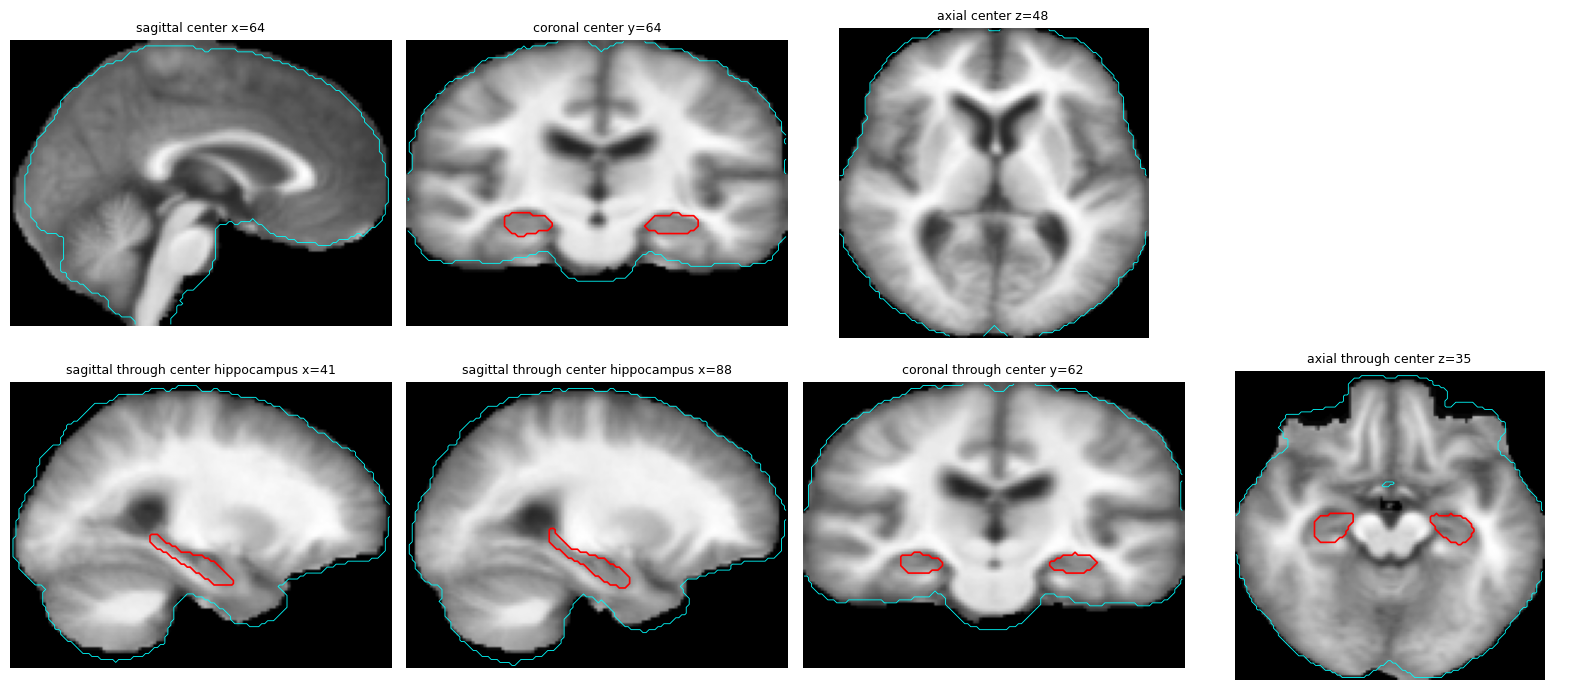

In [9]:
bg = vols.mean(0)
def show(ax, k, i, title):
    img = np.take(bg, i, axis=k).T
    ax.imshow(img, cmap="gray", origin="lower")
    ax.contour(np.take(hip, i, axis=k).T.astype(float), levels=[0.5], colors="red", linewidths=1.2)
    ax.contour(np.take(warped_mni, i, axis=k).T.astype(float), levels=[0.5], colors="cyan", linewidths=0.6)
    ax.set_title(title, fontsize=9); ax.axis("off")

fig, axs = plt.subplots(2, 4, figsize=(16, 7))
show(axs[0, 0], 0, CENTER[0], f"sagittal center x={CENTER[0]}")
show(axs[0, 1], 1, CENTER[1], f"coronal center y={CENTER[1]}")
show(axs[0, 2], 2, CENTER[2], f"axial center z={CENTER[2]}")
axs[0, 3].axis("off")
show(axs[1, 0], 0, cen_x[0], f"sagittal through center hippocampus x={cen_x[0]}")
show(axs[1, 1], 0, cen_x[1], f"sagittal through center hippocampus x={cen_x[1]}")
show(axs[1, 2], 1, cen_y, f"coronal through center y={cen_y}")
show(axs[1, 3], 2, cen_z, f"axial through center z={cen_z}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/hippocampus_overlay.png", dpi=130); plt.show()
table_pos.to_csv(f"{OUT_DIR}/position_check.csv", index=False); table_hip.to_csv(f"{OUT_DIR}/hippocampus_check.csv", index=False)